In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [2]:
#THE AND GATE
inputs = [[0, 0], [0, 1], [1, 0], [1, 1]]
answers = [0, 0, 0, 1]

weights = [0.0, 0.0]
bias = 0.0
learning_rate = 0.1 

for epoch in range(1, 11):
    mistakes = 0
    # 1. Guess
    for x, real in zip(inputs, answers):
        total = bias + x[0] * weights[0] + x[1] * weights[1]
        guess = 1 if total > 0 else 0

        #2. Check
        error = real - guess

        #3. Fix (only changes something when error is not 0)
        if error != 0:
            mistakes = mistakes + 1
            weights[0] = weights[0] + (learning_rate * error * x[0])
            weights[1] = weights[1] + (learning_rate * error * x[1])
            bias = bias + learning_rate * error

    print(f"Epoch {epoch}: mistakes = {mistakes}, weights = {[round(w, 2) for w in weights]}, bias ={round(bias, 2)}")

    if mistakes ==  0:
        print("No more mistakes. The perceptron has learned!")
        break

Epoch 1: mistakes = 1, weights = [0.1, 0.1], bias =0.1
Epoch 2: mistakes = 3, weights = [0.2, 0.1], bias =0.0
Epoch 3: mistakes = 3, weights = [0.2, 0.1], bias =-0.1
Epoch 4: mistakes = 2, weights = [0.2, 0.2], bias =-0.1
Epoch 5: mistakes = 1, weights = [0.2, 0.1], bias =-0.2
Epoch 6: mistakes = 0, weights = [0.2, 0.1], bias =-0.2
No more mistakes. The perceptron has learned!


In [11]:
#Test what it learned
print("A B | answer")
for x in inputs:
    total = bias + x[0] * weights[0] + x[1] * weights[1]
    print(x[0], " ", x[1], " |", 1 if total > 0 else 0)

A B | answer
0   0  | 0
0   1  | 0
1   0  | 0
1   1  | 1


In [3]:
students = pd.read_csv("perc_student.csv")

In [4]:
print(students["passed"].value_counts())

passed
0    33
1    27
Name: count, dtype: int64


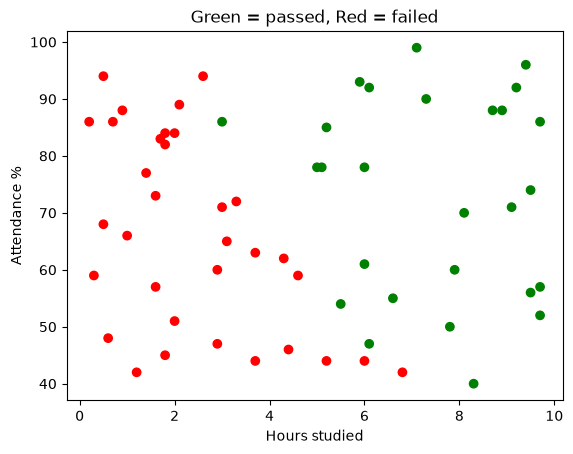

In [5]:
colors = students["passed"].map({0: "red", 1: "green"})
plt.scatter(students["hours_studied"], students["attendance_pct"], c =colors)
plt.xlabel("Hours studied")
plt.ylabel("Attendance %")
plt.title("Green = passed, Red = failed")
plt.show()

In [6]:
#features and label, then split
x = students[["hours_studied", "attendance_pct"]]
y = students["passed"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("Training students:", len(x_train))
print("Testing students:", len(x_test))

Training students: 48
Testing students: 12


In [7]:
#scale the data
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [8]:
#Train the perception
model = Perceptron(random_state=42)
model.fit(x_train_scaled, y_train)

print("Learned weights:", model.coef_.round(2))
print("Leanred bias:", model.intercept_.round(2))

Learned weights: [[4.69 3.04]]
Leanred bias: [0.]


In [9]:
#Test
predictions = model.predict(x_test_scaled)
print("Accuracy:", round(accuracy_score(y_test, predictions), 2))

Accuracy: 0.92


In [10]:
#Predict for a new student
new_student = pd.DataFrame({"hours_studied": [7], "attendance_pct": [80]})
new_scaled = scaler.transform(new_student)

result = model.predict(new_scaled)[0]
print("prediction:", "PASS" if result == 1 else "FAIL")

prediction: PASS


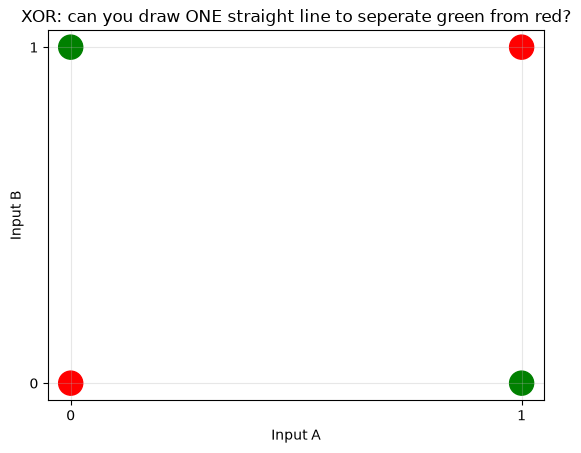

In [12]:
xor_inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
xor_answers = np.array([0, 1, 1, 0])

colors = ["green" if a == 1 else "red" for a in xor_answers]
plt.scatter(xor_inputs[:, 0], xor_inputs[:, 1], c=colors, s=300)
plt.xlabel("Input A")
plt.ylabel("Input B")
plt.title("XOR: can you draw ONE straight line to seperate green from red?")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.grid(alpha=0.3)
plt.show()

In [13]:
xor_model = Perceptron(max_iter=1000, random_state=42)
xor_model.fit(xor_inputs, xor_answers)

xor_predictions = xor_model.predict(xor_inputs)
print("Real answers:", xor_answers)
print("Perceptron: ", xor_predictions)
print("Accuracy:", accuracy_score(xor_answers, xor_predictions))

Real answers: [0 1 1 0]
Perceptron:  [0 0 0 0]
Accuracy: 0.5
